part 1a

theta_LS = [ 0.36653876  1.5006948   0.20814339 -1.59632225  0.30487261 -0.1499845
  1.22721903 -0.00566753]
Validation MSE = 0.34571728

Largest training residuals:
Row       x        Residual     Squared residual
 19    -0.3092      -3.5004          12.2529
 40     0.4503      -2.5961           6.7399
 52     0.7238      -2.5163           6.3320
 42     0.5094      -2.2716           5.1600
 11    -0.5673      -1.8059           3.2613
Share of training SSE from these 5 rows: 76.1%
Legendre: lambda_min = 0.19407839, lambda_max = 61.221536, kappa = 315.44747
Monomial: lambda_min = 0.00050822583, lambda_max = 71.134432, kappa = 139966.19


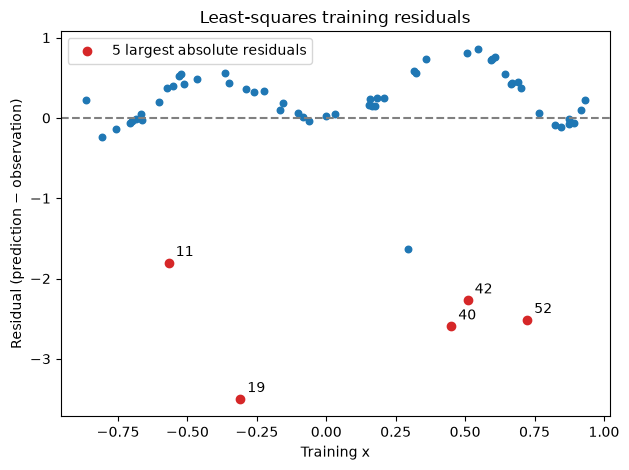

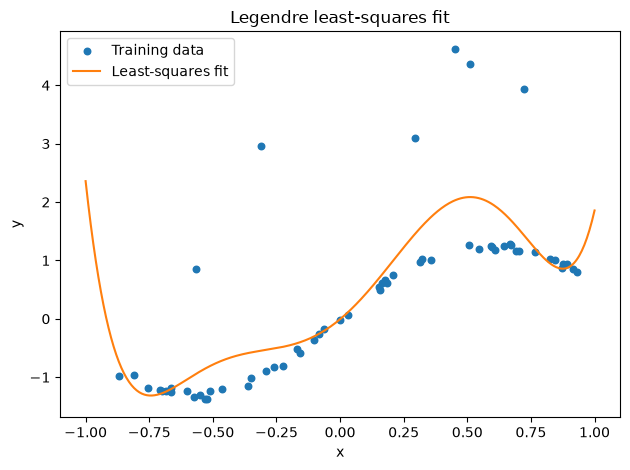

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

data_dir = Path(r".")


def legendre_matrix(x, n=8):
    A = np.empty((len(x), n))
    A[:, 0] = 1.0
    A[:, 1] = x

    for k in range(1, n - 1):
        A[:, k + 1] = (
            (2 * k + 1) * x * A[:, k] - k * A[:, k - 1]
        ) / (k + 1)

    return A


# 1. 用训练数据求最小二乘系数
x_train, b = np.loadtxt(data_dir / "trainingI.dat", unpack=True)
A = legendre_matrix(x_train)
theta_ls = np.linalg.solve(A.T @ A, A.T @ b)

print("theta_LS =", theta_ls)

# 2. 在 [-1, 1] 上计算拟合曲线
x_plot = np.linspace(-1, 1, 400)
y_plot = legendre_matrix(x_plot) @ theta_ls

# 3. 用同一组系数预测验证数据并计算 MSE
x_val, y_val = np.loadtxt(data_dir / "validationI.dat", unpack=True)
y_pred = legendre_matrix(x_val) @ theta_ls
validation_mse = np.mean((y_pred - y_val) ** 2)

print(f"Validation MSE = {validation_mse:.8g}")

# 4. 检查训练残差
residuals = A @ theta_ls - b
squared_residuals = residuals ** 2
largest = np.argsort(np.abs(residuals))[::-1][:5]

print("\nLargest training residuals:")
print("Row       x        Residual     Squared residual")
for i in largest:
    print(f"{i + 1:3d}   {x_train[i]:8.4f}   {residuals[i]:10.4f}"
          f"   {squared_residuals[i]:14.4f}")

sse = squared_residuals.sum()
if sse > 0:
    share = squared_residuals[largest].sum() / sse
    print(f"Share of training SSE from these 5 rows: {share:.1%}")

fig_res, ax_res = plt.subplots()
ax_res.scatter(x_train, residuals, s=22)
ax_res.axhline(0, color="grey", linestyle="--")

ax_res.scatter(x_train[largest], residuals[largest],
               color="tab:red", label="5 largest absolute residuals")
for i in largest:
    ax_res.annotate(
        str(i + 1),
        (x_train[i], residuals[i]),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax_res.set(xlabel="Training x", ylabel="Residual (prediction − observation)",
           title="Least-squares training residuals")
ax_res.legend()
fig_res.tight_layout()

# 每一列依次是 1, x, x**2, ..., x**7
A_mono = np.column_stack([x_train**k for k in range(8)])

for name, B in [("Legendre", A), ("Monomial", A_mono)]:
    eigenvalues = np.linalg.eigvalsh(B.T @ B)
    lambda_min = eigenvalues[0]
    lambda_max = eigenvalues[-1]
    kappa = lambda_max / lambda_min

    print(f"{name}: lambda_min = {lambda_min:.8g}, "
          f"lambda_max = {lambda_max:.8g}, kappa = {kappa:.8g}")

# 在同一张图上画训练散点和拟合曲线
fig, ax = plt.subplots()
ax.scatter(x_train, b, s=22, label="Training data")
ax.plot(x_plot, y_plot, color="tab:orange", label="Least-squares fit")
ax.set(xlabel="x", ylabel="y", title="Legendre least-squares fit")
ax.legend()
fig.tight_layout()
plt.show()
